HEALTHCARE ANALYTICS PROJECT
Length of Stay Prediction using Machine Learning

DATASET INFORMATION

Dataset Shape:
(318438, 18)

Columns in Dataset:
['case_id', 'Hospital_code', 'Hospital_type_code', 'City_Code_Hospital', 'Hospital_region_code', 'Available_Extra_Rooms_in_Hospital', 'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed_Grade', 'patientid', 'City_Code_Patient', 'Type_of_Admission', 'Severity_of_Illness', 'Visitors_with_Patient', 'Age', 'Admission_Deposit', 'Stay']

First 5 Rows:
   case_id  Hospital_code Hospital_type_code  City_Code_Hospital  \
0        1              8                  c                   3   
1        2              2                  c                   5   
2        3             10                  e                   1   
3        4             26                  b                   2   
4        5             26                  b                   2   

  Hospital_region_code  Available_Extra_Rooms_in_Hospital    Department  \
0                

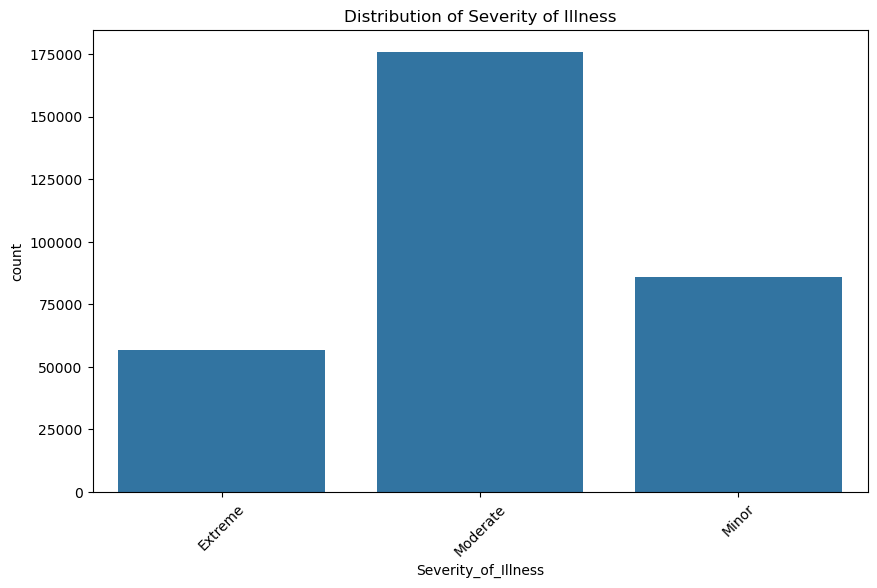

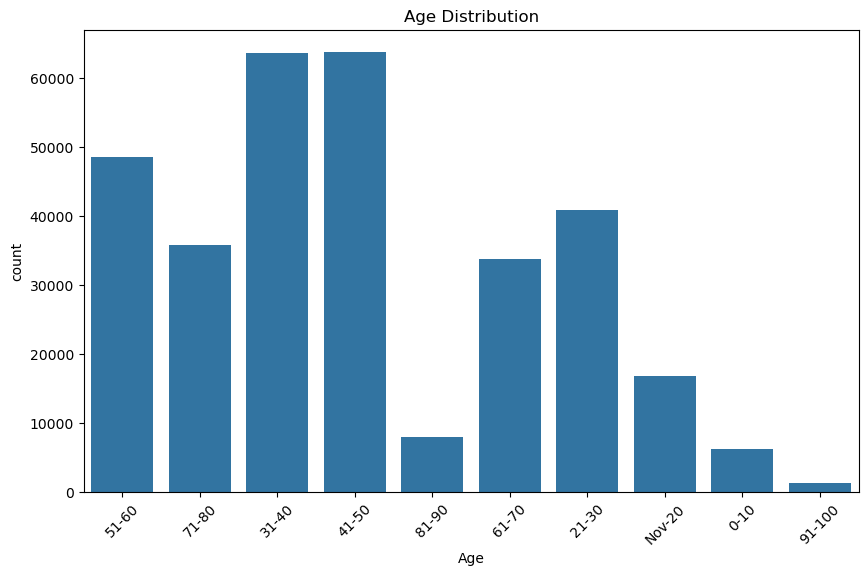

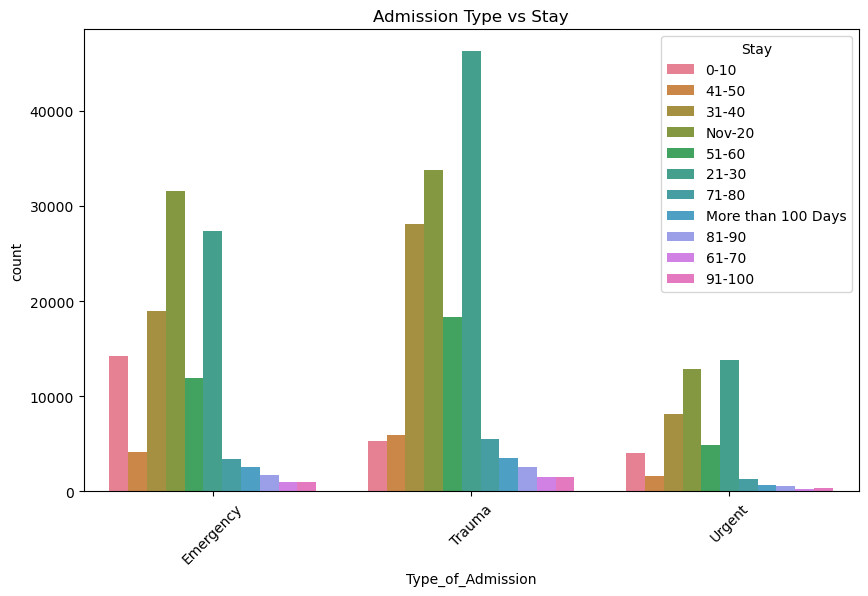

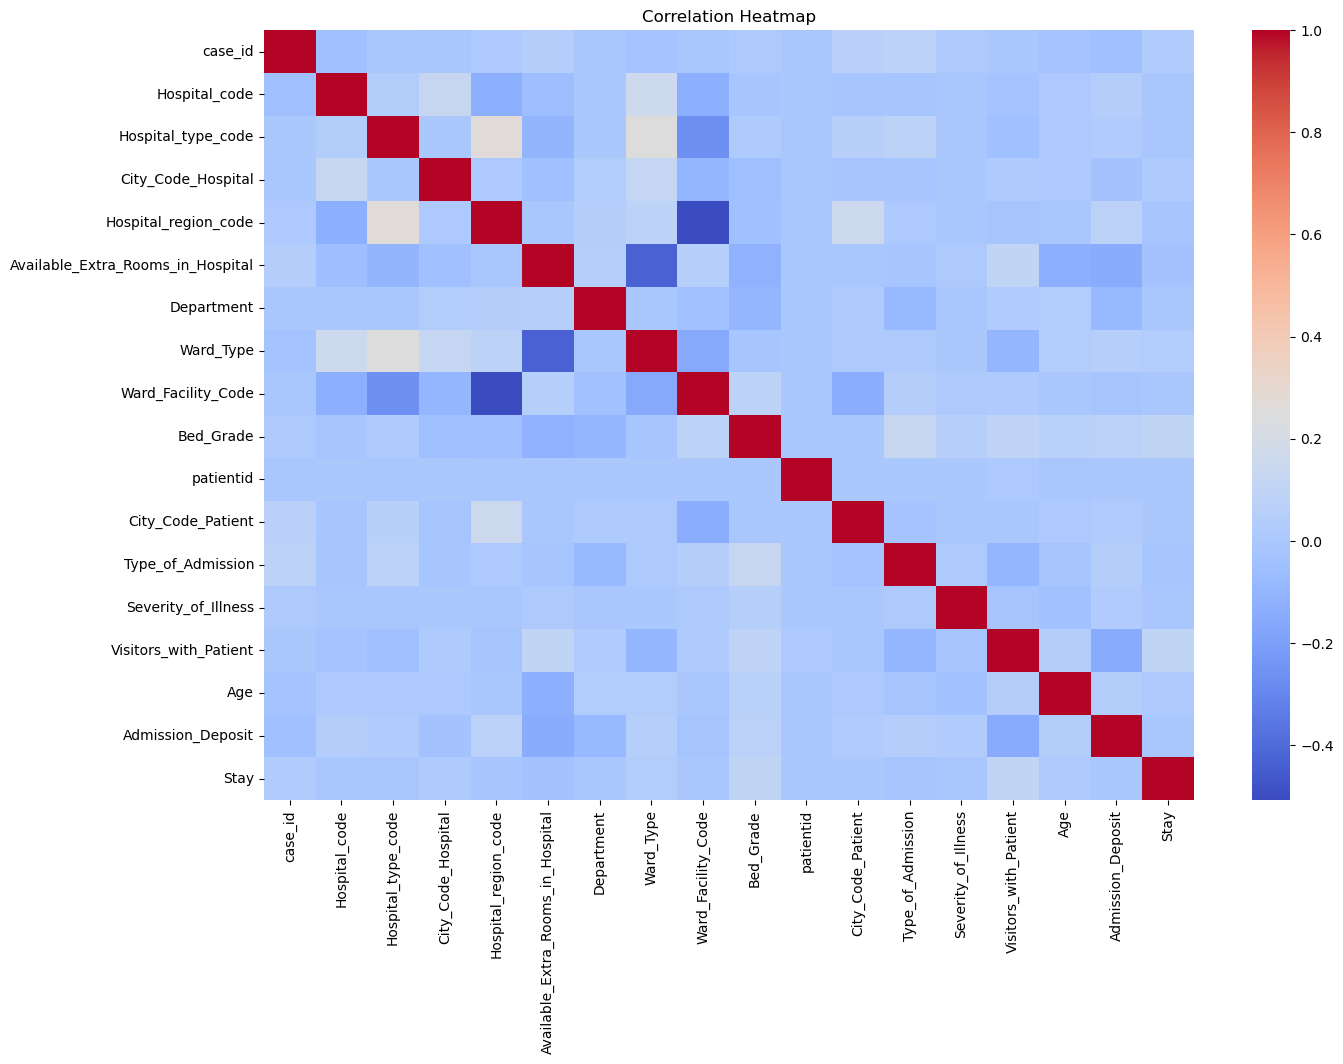


XGBoost is not installed. Skipping XGBoost model.

MODEL TRAINING AND EVALUATION

Training Linear Regression...
Linear Regression Completed

Training Decision Tree...
Decision Tree Completed

Training Random Forest...


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

print("============================================")
print("HEALTHCARE ANALYTICS PROJECT")
print("Length of Stay Prediction using Machine Learning")
print("============================================")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("HealthCareAnalytics.csv")

print("\n====================================")
print("DATASET INFORMATION")
print("====================================")

print("\nDataset Shape:")
print(df.shape)

print("\nColumns in Dataset:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Description:")
print(df.describe(include='all'))

print("\n====================================")
print("HANDLING MISSING VALUES")
print("====================================")

for col in df.columns:

    if df[col].dtype in ['int64', 'float64']:
        df[col].fillna(df[col].median(), inplace=True)

    else:
        df[col].fillna(df[col].mode()[0], inplace=True)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

plt.figure(figsize=(10,6))
sns.countplot(x="Severity_of_Illness", data=df)
plt.title("Distribution of Severity of Illness")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10,6))
sns.countplot(x="Age", data=df)
plt.title("Age Distribution")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10,6))
sns.countplot(x="Type_of_Admission", hue="Stay", data=df)
plt.title("Admission Type vs Stay")
plt.xticks(rotation=45)
plt.show()

from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

label_encoders = {}

for col in df_encoded.select_dtypes(include='object').columns:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le

plt.figure(figsize=(15,10))
sns.heatmap(df_encoded.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

target_column = "Stay"

X = df_encoded.drop(target_column, axis=1)
y = df_encoded[target_column]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

xgb_available = True

try:
    from xgboost import XGBRegressor
except:
    xgb_available = False
    print("\nXGBoost is not installed. Skipping XGBoost model.")

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

if xgb_available:
    models["XGBoost"] = XGBRegressor(random_state=42)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

print("\n====================================")
print("MODEL TRAINING AND EVALUATION")
print("====================================")

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    r2 = r2_score(y_test, y_pred)

    results.append([name, mae, rmse, r2])

    print(f"{name} Completed")

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2 Score"]
)

print("\n====================================")
print("MODEL COMPARISON REPORT")
print("====================================")

print(results_df)

best_model = results_df.loc[results_df["R2 Score"].idxmax()]

print("\n====================================")
print("BEST MODEL FOR PRODUCTION")
print("====================================")

print(best_model)

plt.figure(figsize=(10,6))

sns.barplot(
    x="Model",
    y="R2 Score",
    data=results_df
)

plt.title("Model Performance Comparison")
plt.xticks(rotation=45)
plt.show()

print("\n====================================")
print("FINAL PROJECT REPORT")
print("====================================")

print("""

PROJECT TITLE:
Healthcare Analytics - Length of Stay Prediction

PROJECT OBJECTIVE:
The objective of this project is to predict the hospital stay duration
of patients using machine learning algorithms.

DATASET DETAILS:
Dataset Name: HealthCareAnalytics.csv

TECHNIQUES USED:
1. Data Cleaning
2. Missing Value Handling
3. Label Encoding
4. Feature Scaling
5. Exploratory Data Analysis (EDA)
6. Machine Learning Model Training
7. Model Evaluation

MODELS USED:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. XGBoost Regressor

EVALUATION METRICS:
1. MAE (Mean Absolute Error)
2. RMSE (Root Mean Squared Error)
3. R2 Score

CHALLENGES FACED:
1. Missing values in categorical and numerical columns.
   Solution:
   Used Median for numerical columns and Mode for categorical columns.

2. Large number of categorical features.
   Solution:
   Applied Label Encoding.

3. Feature scaling issues.
   Solution:
   Used StandardScaler.

4. Model performance optimization.
   Solution:
   Compared multiple machine learning models.

CONCLUSION:
The project successfully predicts patient length of stay
using machine learning algorithms.
The best-performing model can be used for healthcare
resource planning and hospital management.

""")

print("====================================")
print("PROJECT EXECUTION COMPLETED")
print("====================================")